# Temp: a look at `song_bow` and `song_bow_coverage`

Scratch notebook for exploring the lyrics input to LDA. Not part of the pipeline.
This notebook is generated with Claude for the purpose of data exploration - to visualize our data quickly.

- `data/song_bow.parquet`: one row per (song, word), with the word's count summed over the song's tracks.
- `data/song_bow_coverage.parquet`: one row per song in the filtered set, and whether it has lyrics at all.

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

DATA = "data"
BLUE, GREY, INK, MUTED = "#2a78d6", "#898781", "#0b0b0b", "#52514e"
THOUSANDS = plt.FuncFormatter(lambda v, _: f"{v:,.0f}")

plt.rcParams.update({
    "figure.figsize": (8, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlesize": 12, "axes.titleweight": "bold",
})

bow = pd.read_parquet(f"{DATA}/song_bow.parquet")
cov = pd.read_parquet(f"{DATA}/song_bow_coverage.parquet")

## 1. What the tables look like

In [6]:
for name, df in [("song_bow", bow), ("song_bow_coverage", cov)]:
    print(f"{name}: {df.shape[0]:,} rows x {df.shape[1]} columns")
    print(df.dtypes.to_string(), "\n")
    print("missing values:", df.isna().sum().to_dict(), "\n")

song_bow: 3,089,431 rows x 4 columns
song        int64
word          str
count       int64
n_tracks    int64 

missing values: {'song': 0, 'word': 0, 'count': 0, 'n_tracks': 0} 

song_bow_coverage: 64,519 rows x 5 columns
song            int32
song_id           str
n_tracks        int64
n_bow_tracks    int64
has_bow          bool 

missing values: {'song': 0, 'song_id': 0, 'n_tracks': 0, 'n_bow_tracks': 0, 'has_bow': 0} 



In [7]:
bow.head(10)

,song,word,count,n_tracks
0,1,a,1,1
1,1,am,5,1
2,1,and,1,1
3,1,be,8,1
4,1,believ,1,1
5,1,bring,1,1
6,1,caus,2,1
7,1,cold,1,1
8,1,do,1,1
9,1,for,1,1


In [4]:
cov.head(10)

,song,song_id,n_tracks,n_bow_tracks,has_bow
0,0,SOAKIMP12A8C130995,1,0,False
1,1,SOAPDEY12A81C210A9,1,1,True
2,2,SOBBMDR12A8C13253B,1,0,False
3,3,SOBFNSP12AF72A0E22,1,1,True
4,4,SOBFOVM12A58A7D494,1,0,False
5,6,SOBSUJE12A6D4F8CF5,1,0,False
6,8,SOBXALG12A8C13C108,1,1,True
7,9,SOBXHDL12A81C204C0,2,0,False
8,10,SOBYHAJ12A6701BF1D,1,1,True
9,11,SOCNMUH12A6D4F6E6D,1,1,True


## 2. Coverage: how many songs have lyrics?

Only songs with at least one track in the musiXmatch dataset have a bag of words.

35,690 of 64,519 songs have lyrics (55.3%)
songs in song_bow: 35,690


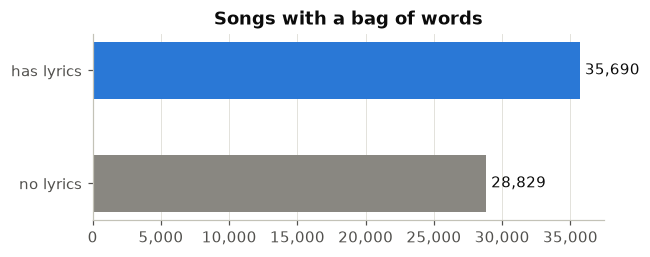

In [5]:
n, n_bow = len(cov), int(cov["has_bow"].sum())
print(f"{n_bow:,} of {n:,} songs have lyrics ({n_bow / n:.1%})")
print(f"songs in song_bow: {bow['song'].nunique():,}")

fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh(["no lyrics", "has lyrics"], [n - n_bow, n_bow], color=[GREY, BLUE], height=0.5)
for y, v in enumerate([n - n_bow, n_bow]):
    ax.text(v, y, f" {v:,}", va="center", color=INK)
ax.set_title("Songs with a bag of words")
ax.xaxis.set_major_formatter(THOUSANDS)
ax.grid(axis="y", visible=False)
plt.show()

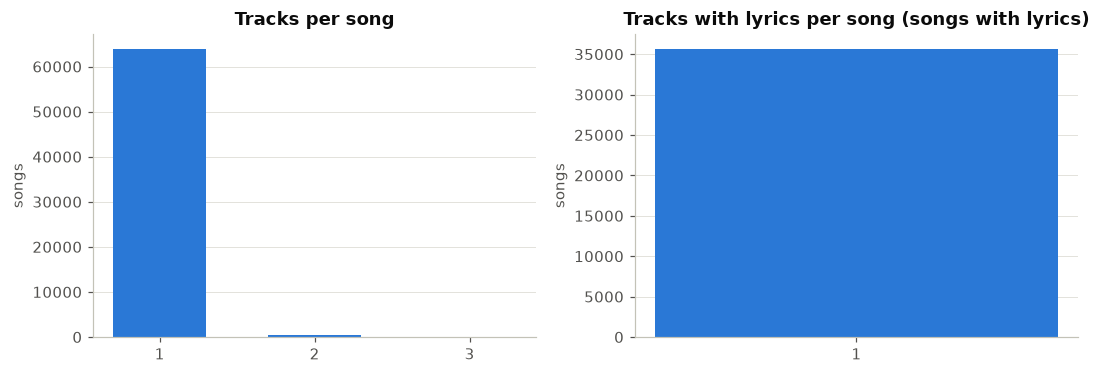

In [6]:
# Songs can have several tracks (versions); how many of them have lyrics?
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col, title in [(axes[0], "n_tracks", "Tracks per song"),
                       (axes[1], "n_bow_tracks", "Tracks with lyrics per song (songs with lyrics)")]:
    data = cov[col] if col == "n_tracks" else cov.loc[cov["has_bow"], col]
    vc = data.clip(upper=5).value_counts().sort_index()
    ax.bar([str(i) if i < 5 else "5+" for i in vc.index], vc.values, color=BLUE, width=0.6)
    ax.set_title(title)
    ax.set_ylabel("songs")
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## 3. Song length

        tokens  distinct_words
count  35690.0         35690.0
mean     244.2            86.6
std      147.8            45.5
min        1.0             1.0
25%      149.0            59.0
50%      216.0            79.0
75%      302.0           102.0
max     3422.0           594.0


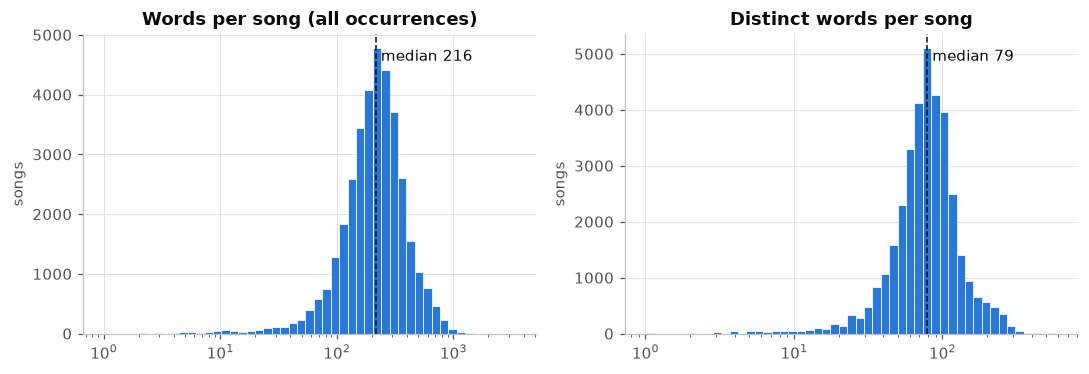

In [7]:
per_song = bow.groupby("song").agg(tokens=("count", "sum"), distinct_words=("word", "size"))
print(per_song.describe().round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col, title in [(axes[0], "tokens", "Words per song (all occurrences)"),
                       (axes[1], "distinct_words", "Distinct words per song")]:
    ax.hist(per_song[col], bins=np.logspace(0, np.log10(per_song[col].max()), 50), color=BLUE,
            edgecolor="white", linewidth=0.5)
    ax.axvline(per_song[col].median(), color=INK, linewidth=1, linestyle="--")
    ax.text(per_song[col].median(), ax.get_ylim()[1] * 0.95, f" median {per_song[col].median():.0f}",
            color=INK, va="top")
    ax.set_xscale("log")
    ax.set_title(title)
    ax.set_ylabel("songs")
plt.tight_layout()
plt.show()

## 4. Words

Two ways to measure how common a word is: total count (all occurrences) and document frequency
(share of songs that contain it). Note the vocabulary is **stemmed**, e.g. `babi` for "baby".

4,999 distinct words in the vocabulary, 8,713,838 word occurrences


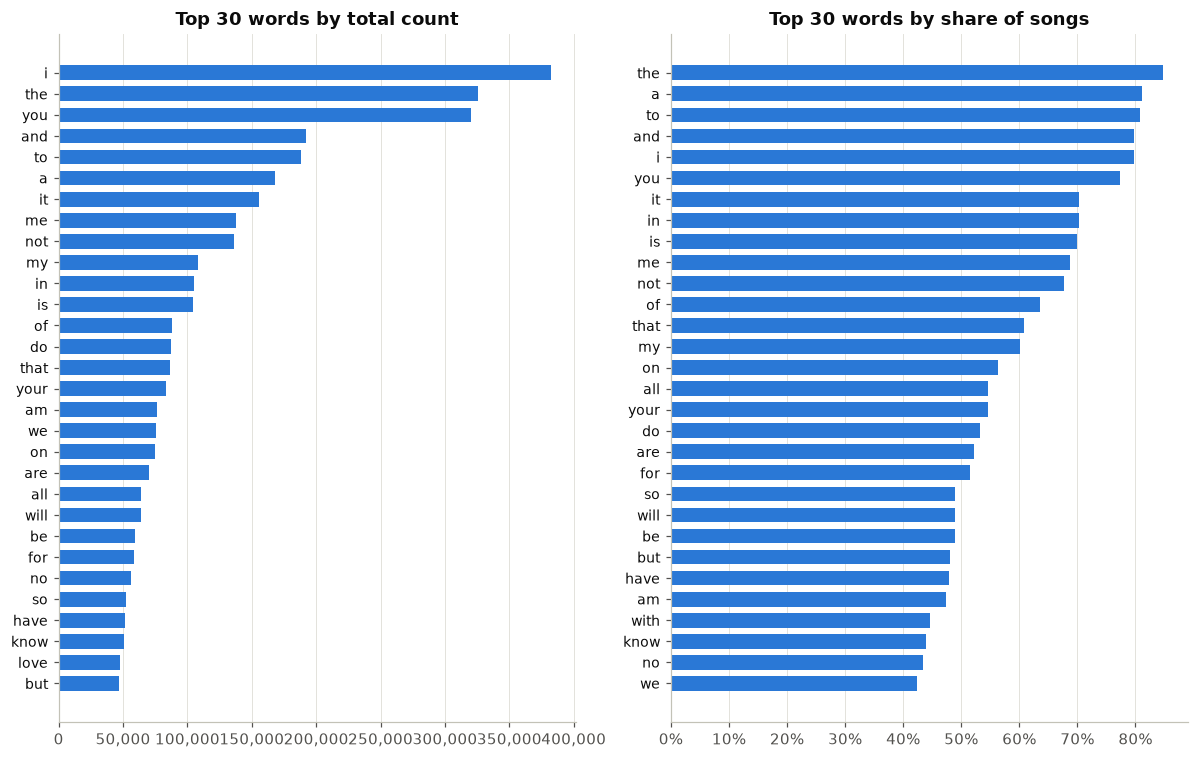

In [8]:
n_songs = bow["song"].nunique()
words = bow.groupby("word").agg(total=("count", "sum"), songs=("song", "size"))
words["share_of_songs"] = words["songs"] / n_songs
print(f"{len(words):,} distinct words in the vocabulary, {int(words['total'].sum()):,} word occurrences")

fig, axes = plt.subplots(1, 2, figsize=(11, 7))
for ax, col, title, fmt in [(axes[0], "total", "Top 30 words by total count", "{:,.0f}"),
                            (axes[1], "share_of_songs", "Top 30 words by share of songs", "{:.0%}")]:
    top = words[col].nlargest(30)[::-1]
    ax.barh(top.index, top.values, color=BLUE, height=0.7)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=9, labelcolor=INK)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}") if col == "share_of_songs" else THOUSANDS)
plt.tight_layout()
plt.show()

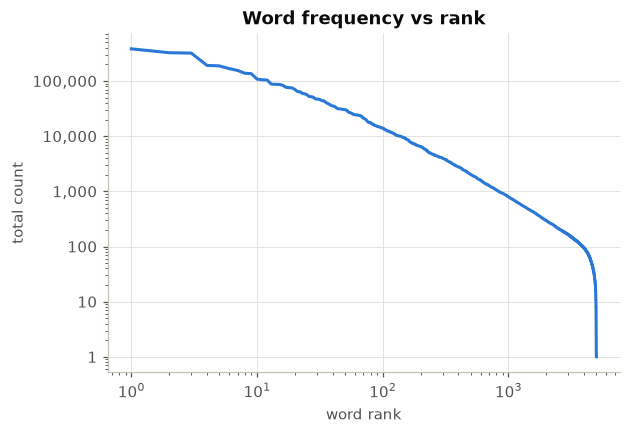

In [9]:
# Zipf's law: a few words are very common, most are rare. On log-log axes this is close to a straight line.
ranked = words["total"].sort_values(ascending=False).to_numpy()
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(np.arange(1, len(ranked) + 1), ranked, color=BLUE, linewidth=2)
ax.set_xlabel("word rank")
ax.set_ylabel("total count")
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_title("Word frequency vs rank")
plt.show()

## 5. What `scripts/run_lda.py` removes before fitting

Same rules as `scripts/run_lda.py` (copied here, because importing it needs numba): drop stop words and lyric
fillers, words in more than `MAX_DF` of songs, words in fewer than `MIN_DF` songs, then songs left with
fewer than `MIN_TOKENS` words. **If you change the rules in `scripts/run_lda.py`, change them here too.**

In [10]:
FILLERS = {"oh", "ooh", "yeah", "yea", "la", "na", "da", "hey", "uh", "ah", "whoa", "mmm", "ha",
           "doo", "ya", "yo", "huh", "woah", "ohh", "ay", "eh", "im", "dont", "aint", "caus", "gonna",
           "wanna", "got", "get", "let", "just", "like"}
STOP = set(ENGLISH_STOP_WORDS) | FILLERS
MAX_DF, MIN_DF, MIN_TOKENS = 0.4, 20, 20

words["reason"] = np.select(
    [words.index.isin(STOP), words["share_of_songs"] > MAX_DF, words["songs"] < MIN_DF],
    ["stop word / filler", f"in > {MAX_DF:.0%} of songs", f"in < {MIN_DF} songs"], default="kept")
summary = words.groupby("reason").agg(words=("total", "size"), occurrences=("total", "sum"))
summary["share_of_occurrences"] = (summary["occurrences"] / summary["occurrences"].sum()).round(3)
print(summary.sort_values("occurrences", ascending=False).to_string())

kept = words.index[words["reason"] == "kept"]
kept_tokens = bow[bow["word"].isin(kept)].groupby("song")["count"].sum()
n_left = int((kept_tokens >= MIN_TOKENS).sum())
print(f"\nsongs left with >= {MIN_TOKENS} kept words: {n_left:,} of {n_songs:,}")

                    words  occurrences  share_of_occurrences
reason                                                      
stop word / filler    237      5286663                 0.607
kept                 4495      3368076                 0.387
in > 40% of songs       1        50897                 0.006
in < 20 songs         266         8202                 0.001



songs left with >= 20 kept words: 34,816 of 35,690


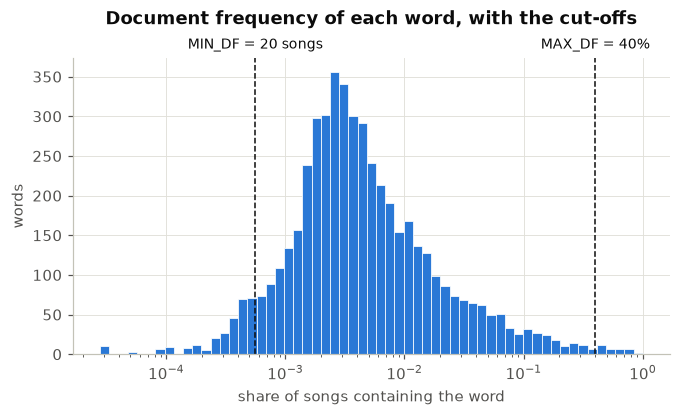

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(words["share_of_songs"], bins=np.logspace(np.log10(words["share_of_songs"].min()), 0, 60),
        color=BLUE, edgecolor="white", linewidth=0.5)
for x, label in [(MAX_DF, f"MAX_DF = {MAX_DF:.0%}"), (MIN_DF / n_songs, f"MIN_DF = {MIN_DF} songs")]:
    ax.axvline(x, color=INK, linewidth=1, linestyle="--")
    ax.text(x, ax.get_ylim()[1] * 1.02, label, color=INK, ha="center", va="bottom", fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("share of songs containing the word")
ax.set_ylabel("words")
ax.set_title("Document frequency of each word, with the cut-offs", pad=22)
plt.show()

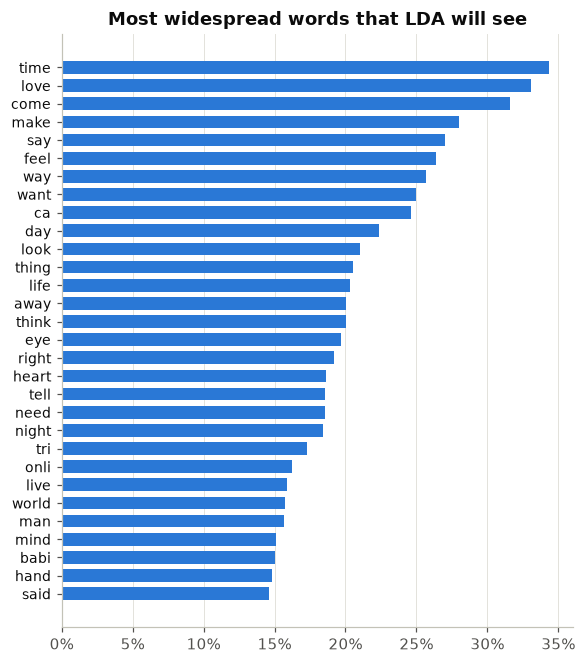

In [12]:
top_kept = words.loc[kept, "share_of_songs"].nlargest(30)[::-1]
fig, ax = plt.subplots(figsize=(6, 7))
ax.barh(top_kept.index, top_kept.values, color=BLUE, height=0.7)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Most widespread words that LDA will see")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=9, labelcolor=INK)
plt.show()

## 6. One song up close

In [13]:
SONG = per_song.index[per_song["tokens"].sub(per_song["tokens"].median()).abs().argmin()]  # a typical-length song
song_words = bow[bow["song"] == SONG].sort_values("count", ascending=False)
print(f"song {SONG}  ({cov.loc[cov['song'] == SONG, 'song_id'].item()}): "
      f"{song_words['count'].sum()} words, {len(song_words)} distinct")
song_words.assign(kept=song_words["word"].isin(kept))[["word", "count", "kept"]].head(25)

song 441  (SONLCTW12A58A7BB70): 216 words, 56 distinct


,word,count,kept
22272,you,23,False
22234,i,16,False
22246,move,15,False
22261,the,9,False
22245,me,8,False
22217,a,8,False
22238,keep,7,False
22271,with,7,False
22240,lazi,6,True
22270,wish,6,True
